
# Phase 9B — Synthetic Gold Tasks for End-to-End Validation

The real tasks currently produce flat subset surfaces.

This notebook creates **nonce / synthetic tasks** whose answers cannot come from pretraining memory.  
The purpose is not to benchmark language ability; it is to validate the entire pipeline:

\[
\text{mask construction}
\rightarrow
\text{prompt rendering}
\rightarrow
\text{scoring}
\rightarrow
F(S)
\rightarrow
\text{Möbius / Walsh / Laplacian}.
\]

The crucial family is a **pure pair dependency**:

\[
F(\emptyset)\approx0,\quad
F(\{1\})\approx0,\quad
F(\{2\})\approx0,\quad
F(\{1,2\})\approx1.
\]

That should create genuine order-2 structure.


In [1]:

from dataclasses import dataclass, asdict
from itertools import product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

@dataclass
class SyntheticTask:
    task_id: str
    family: str
    question: str
    gold: str
    evidence_cards: list

TASKS = [
    SyntheticTask(
        task_id="direct_0",
        family="direct",
        question="Which object does the nonce entity Varkel possess?",
        gold="amber prism",
        evidence_cards=[
            "Varkel possesses the amber prism.",
            "Nuvet is located north of Pelor.",
            "Tessim prefers green objects.",
            "Korda visited the silent tower.",
        ],
    ),
    SyntheticTask(
        task_id="pair_chain_0",
        family="pair_chain",
        question="What color is the object owned by Zorblax?",
        gold="violet",
        evidence_cards=[
            "Zorblax owns object K-17.",
            "Object K-17 is violet.",
            "Object M-42 is silver.",
            "Ruvin owns object P-3.",
        ],
    ),
    SyntheticTask(
        task_id="triple_chain_0",
        family="triple_chain",
        question="In which city is the token carried by Mervak located?",
        gold="Talune",
        evidence_cards=[
            "Mervak carries token T9.",
            "Token T9 is stored in vault V4.",
            "Vault V4 is in Talune.",
            "Vault R2 is in Doram.",
        ],
    ),
    SyntheticTask(
        task_id="redundant_0",
        family="redundant",
        question="What shape is Neral's badge?",
        gold="hexagonal",
        evidence_cards=[
            "Neral's badge is hexagonal.",
            "The badge belonging to Neral has six equal sides.",
            "Pevin's badge is circular.",
            "Aru's badge is triangular.",
        ],
    ),
    SyntheticTask(
        task_id="dual_path_0",
        family="dual_path",
        question="Where is the crystal associated with Joval?",
        gold="Orin",
        evidence_cards=[
            "Joval is linked to case C8.",
            "Case C8 points to Orin.",
            "Joval is registered under route R5.",
            "Route R5 terminates in Orin.",
        ],
    ),
]

pd.DataFrame([asdict(t) for t in TASKS])


,task_id,family,question,gold,evidence_cards
0,direct_0,direct,Which object does the nonce entity Varkel poss...,amber prism,"[Varkel possesses the amber prism., Nuvet is l..."
1,pair_chain_0,pair_chain,What color is the object owned by Zorblax?,violet,"[Zorblax owns object K-17., Object K-17 is vio..."
2,triple_chain_0,triple_chain,In which city is the token carried by Mervak l...,Talune,"[Mervak carries token T9., Token T9 is stored ..."
3,redundant_0,redundant,What shape is Neral's badge?,hexagonal,"[Neral's badge is hexagonal., The badge belong..."
4,dual_path_0,dual_path,Where is the crystal associated with Joval?,Orin,"[Joval is linked to case C8., Case C8 points t..."



## 1. Enumerate all 16 masks and render prompts

`mask=0` contains **no evidence**.  
`mask=15` contains all four cards.


In [3]:

N_EVIDENCE = 4
N_STATES = 2**N_EVIDENCE

def subset_from_mask(cards, mask):
    return [cards[i] for i in range(len(cards)) if (mask >> i) & 1]

def render_prompt(task, mask):
    selected = subset_from_mask(task.evidence_cards, mask)
    ctx = "\n".join(f"- {x}" for x in selected)
    if not ctx:
        ctx = "[NO EVIDENCE]"
    return (
        "Use only the supplied evidence. If it is insufficient, answer UNKNOWN.\n\n"
        f"Evidence:\n{ctx}\n\n"
        f"Question: {task.question}\n"
        "Answer with only the answer."
    )

rows = []
for task in TASKS:
    for mask in range(N_STATES):
        rows.append({
            "task_id": task.task_id,
            "family": task.family,
            "mask": mask,
            "gold": task.gold,
            "selected_evidence": subset_from_mask(task.evidence_cards, mask),
            "prompt": render_prompt(task, mask),
        })

synthetic_prompts = pd.DataFrame(rows)
display(synthetic_prompts.head(20))
synthetic_prompts.to_json("phase9b_synthetic_prompts.jsonl", orient="records", lines=True)


,task_id,family,mask,gold,selected_evidence,prompt
0,direct_0,direct,0,amber prism,[],Use only the supplied evidence. If it is insuf...
1,direct_0,direct,1,amber prism,[Varkel possesses the amber prism.],Use only the supplied evidence. If it is insuf...
2,direct_0,direct,2,amber prism,[Nuvet is located north of Pelor.],Use only the supplied evidence. If it is insuf...
3,direct_0,direct,3,amber prism,"[Varkel possesses the amber prism., Nuvet is l...",Use only the supplied evidence. If it is insuf...
4,direct_0,direct,4,amber prism,[Tessim prefers green objects.],Use only the supplied evidence. If it is insuf...
5,direct_0,direct,5,amber prism,"[Varkel possesses the amber prism., Tessim pre...",Use only the supplied evidence. If it is insuf...
6,direct_0,direct,6,amber prism,"[Nuvet is located north of Pelor., Tessim pref...",Use only the supplied evidence. If it is insuf...
7,direct_0,direct,7,amber prism,"[Varkel possesses the amber prism., Nuvet is l...",Use only the supplied evidence. If it is insuf...
8,direct_0,direct,8,amber prism,[Korda visited the silent tower.],Use only the supplied evidence. If it is insuf...
9,direct_0,direct,9,amber prism,"[Varkel possesses the amber prism., Korda visi...",Use only the supplied evidence. If it is insuf...



## 2. Structural oracle

Before calling any model, define what evidence is *logically sufficient*.

This gives an expected subset function \(F^\star(S)\) for validating the spectral machinery.


In [4]:

REQUIRED_SETS = {
    "direct_0": [{0}],
    "pair_chain_0": [{0,1}],
    "triple_chain_0": [{0,1,2}],
    "redundant_0": [{0}, {1}],
    "dual_path_0": [{0,1}, {2,3}],
}

def mask_to_set(mask):
    return {i for i in range(N_EVIDENCE) if (mask >> i) & 1}

def structural_oracle(task_id, mask):
    S = mask_to_set(mask)
    return float(any(req.issubset(S) for req in REQUIRED_SETS[task_id]))

synthetic_prompts["oracle_F"] = [
    structural_oracle(tid, m)
    for tid, m in zip(synthetic_prompts["task_id"], synthetic_prompts["mask"])
]

display(
    synthetic_prompts[
        ["task_id","family","mask","oracle_F"]
    ].head(32)
)


,task_id,family,mask,oracle_F
0,direct_0,direct,0,0.0
1,direct_0,direct,1,1.0
2,direct_0,direct,2,0.0
3,direct_0,direct,3,1.0
4,direct_0,direct,4,0.0
5,direct_0,direct,5,1.0
6,direct_0,direct,6,0.0
7,direct_0,direct,7,1.0
8,direct_0,direct,8,0.0
9,direct_0,direct,9,1.0



## 3. Provider hook

Replace `provider_call(prompt)` with your actual local/API model call.

The function should return at least:

```python
{"answer": "..."}
```

and, if available, also:

```python
{
    "answer": "...",
    "logprob_gold": ...,
    "confidence": ...,
}
```

For debugging without a provider, keep `DRY_RUN=True`; the notebook then uses the structural oracle as the observed score.


In [5]:

DRY_RUN = True
N_REPEATS = 1

def normalize_answer(x):
    return str(x).strip().lower()

def provider_call(prompt, gold=None):
    raise NotImplementedError("Connect your provider here.")

obs_rows = []

for _, row in synthetic_prompts.iterrows():
    for repeat_id in range(N_REPEATS):
        if DRY_RUN:
            correct = row["oracle_F"]
            answer = row["gold"] if correct == 1.0 else "UNKNOWN"
            extra = {}
        else:
            out = provider_call(row["prompt"], gold=row["gold"])
            answer = out["answer"]
            correct = float(
                normalize_answer(answer) == normalize_answer(row["gold"])
            )
            extra = {
                k: out[k]
                for k in ["logprob_gold", "confidence", "margin"]
                if k in out
            }

        obs_rows.append({
            "task_id": row["task_id"],
            "family": row["family"],
            "mask": int(row["mask"]),
            "repeat_id": repeat_id,
            "gold": row["gold"],
            "answer": answer,
            "correct": correct,
            **extra,
        })

observed = pd.DataFrame(obs_rows)
display(observed.head(20))
observed.to_csv("phase9b_synthetic_observed.csv", index=False)


,task_id,family,mask,repeat_id,gold,answer,correct
0,direct_0,direct,0,0,amber prism,UNKNOWN,0.0
1,direct_0,direct,1,0,amber prism,amber prism,1.0
2,direct_0,direct,2,0,amber prism,UNKNOWN,0.0
3,direct_0,direct,3,0,amber prism,amber prism,1.0
4,direct_0,direct,4,0,amber prism,UNKNOWN,0.0
5,direct_0,direct,5,0,amber prism,amber prism,1.0
6,direct_0,direct,6,0,amber prism,UNKNOWN,0.0
7,direct_0,direct,7,0,amber prism,amber prism,1.0
8,direct_0,direct,8,0,amber prism,UNKNOWN,0.0
9,direct_0,direct,9,0,amber prism,amber prism,1.0



## 4. End-to-end subset surface


In [6]:

surface = (
    observed
    .groupby(["task_id","family","mask"])
    .agg(
        F=("correct","mean"),
        n=("correct","size"),
    )
    .reset_index()
)

diag = (
    surface
    .groupby(["task_id","family"])
    .agg(
        n_masks=("mask","nunique"),
        min_F=("F","min"),
        max_F=("F","max"),
        std_F=("F", lambda x: float(np.std(x.to_numpy(float), ddof=0))),
        n_unique=("F", lambda x: len(np.unique(np.round(x.to_numpy(float), 12)))),
    )
    .reset_index()
)
diag["range_F"] = diag["max_F"] - diag["min_F"]
display(diag)


,task_id,family,n_masks,min_F,max_F,std_F,n_unique,range_F
0,direct_0,direct,16,0.0,1.0,0.500000,2,1.0
1,dual_path_0,dual_path,16,0.0,1.0,0.496078,2,1.0
2,pair_chain_0,pair_chain,16,0.0,1.0,0.433013,2,1.0
3,redundant_0,redundant,16,0.0,1.0,0.433013,2,1.0
4,triple_chain_0,triple_chain,16,0.0,1.0,0.330719,2,1.0



## 5. Walsh energy by order

A pair-chain oracle should contain nontrivial order-2 energy.  
A triple-chain oracle should extend to order 3.


,order,energy,task_id,family
0,0,0.250000,direct_0,direct
1,1,0.250000,direct_0,direct
2,2,0.000000,direct_0,direct
3,3,0.000000,direct_0,direct
4,4,0.000000,direct_0,direct
5,0,0.191406,dual_path_0,dual_path
6,1,0.140625,dual_path_0,dual_path
7,2,0.085938,dual_path_0,dual_path
8,3,0.015625,dual_path_0,dual_path
9,4,0.003906,dual_path_0,dual_path


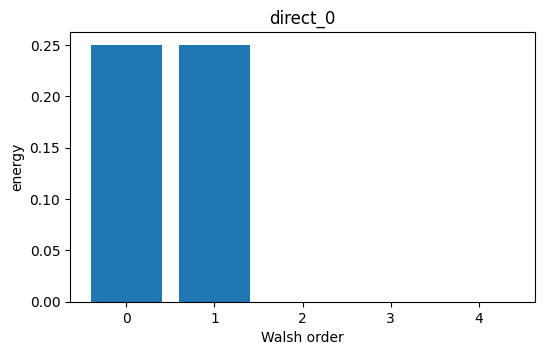

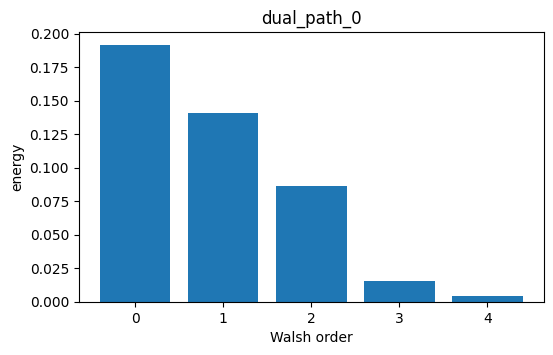

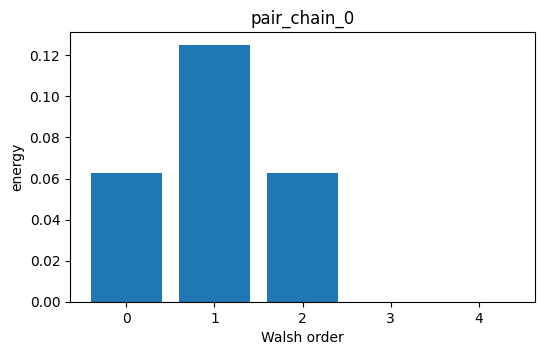

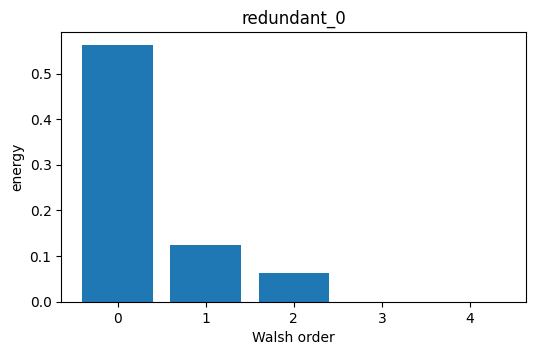

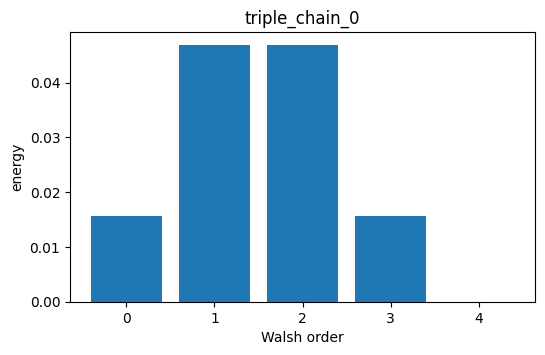

In [7]:

def fwht(a):
    a = np.asarray(a, dtype=float).copy()
    h = 1
    n = len(a)
    while h < n:
        for i in range(0, n, 2*h):
            x = a[i:i+h].copy()
            y = a[i+h:i+2*h].copy()
            a[i:i+h] = x+y
            a[i+h:i+2*h] = x-y
        h *= 2
    return a

def popcount(x):
    return int(x).bit_count()

def walsh_energy_by_order(f, d=4):
    coeff = fwht(np.asarray(f,float)) / len(f)
    rows = []
    for order in range(d+1):
        idx = [i for i in range(2**d) if popcount(i)==order]
        rows.append({
            "order": order,
            "energy": float(np.sum(coeff[idx]**2)),
        })
    return pd.DataFrame(rows)

energy_rows = []
for (task_id, family), g in surface.groupby(["task_id","family"]):
    g = g.sort_values("mask")
    f = g["F"].to_numpy(float)
    e = walsh_energy_by_order(f, 4)
    e["task_id"] = task_id
    e["family"] = family
    energy_rows.append(e)

energy = pd.concat(energy_rows, ignore_index=True)
display(energy)

for task_id, g in energy.groupby("task_id"):
    plt.figure(figsize=(6,3.5))
    plt.bar(g["order"], g["energy"])
    plt.xlabel("Walsh order")
    plt.ylabel("energy")
    plt.title(task_id)
    plt.show()



## 6. Pass/fail gate

The end-to-end pipeline is ready for real tasks only if:

- `mask=0` and `mask=15` prompts differ as expected;
- nonce answers are not produced reliably without sufficient evidence;
- pair-chain shows nonzero order-2 structure;
- triple-chain shows higher-order structure;
- redundant and dual-path families behave differently from simple chains.

This is the strongest protection against interpreting a flat real-data signal as a property of the model.
